<a href="https://colab.research.google.com/github/ChiBinh123/NhapMonHocMay/blob/main/Baitap2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Vui lòng chọn file dữ liệu:


Saving flights.csv to flights (1).csv
-> Đang sử dụng file: flights (1).csv
-> Đọc dữ liệu thành công!
Dữ liệu lớn, lấy ngẫu nhiên 20.000 dòng để xử lý.

--- 5 DÒNG ĐẦU TIÊN ---


,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,AIRLINE_ID,TAIL_NUM,ORIGIN,ORIGIN_CITY_NAME,ORIGIN_STATE_NM,...,TAXI_OUT,TAXI_IN,CRS_ARR_TIME,ARR_TIME,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE
0,1,30,1,2017-01-30,19393,N481WN,SMF,"Sacramento, CA",California,SNA,...,4.0,1725,1722.0,0.0,0.0,80.0,80.0,65.0,404.0,NaN
1,2,7,2,2017-02-07,19790,N348NB,DCA,"Washington, DC",Virginia,JFK,...,7.0,718,655.0,0.0,0.0,78.0,59.0,39.0,213.0,NaN
2,8,13,7,2017-08-13,19393,N8685B,BWI,"Baltimore, MD",Maryland,SAN,...,4.0,1110,1113.0,0.0,0.0,320.0,323.0,309.0,2295.0,NaN
3,1,21,6,2017-01-21,19790,N929AT,JFK,"New York, NY",New York,PBI,...,4.0,1227,1208.0,0.0,0.0,202.0,175.0,138.0,1028.0,NaN
4,10,8,7,2017-10-08,19393,N242WN,PDX,"Portland, OR",Oregon,DEN,...,8.0,1005,1017.0,0.0,0.0,145.0,142.0,117.0,991.0,NaN



--- THÔNG TIN DỮ LIỆU ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   YEAR                 20000 non-null  int64  
 1   MONTH                20000 non-null  int64  
 2   DAY_OF_MONTH         20000 non-null  int64  
 3   DAY_OF_WEEK          20000 non-null  object 
 4   FL_DATE              20000 non-null  int64  
 5   AIRLINE_ID           19963 non-null  object 
 6   TAIL_NUM             20000 non-null  object 
 7   ORIGIN               20000 non-null  object 
 8   ORIGIN_CITY_NAME     20000 non-null  object 
 9   ORIGIN_STATE_NM      20000 non-null  object 
 10  DEST                 20000 non-null  object 
 11  DEST_CITY_NAME       20000 non-null  object 
 12  DEST_STATE_NM        20000 non-null  int64  
 13  CRS_DEP_TIME         19754 non-null  float64
 14  DEP_TIME             19750 non-null  float64
 15  TAXI_OUT 

,Mô hình,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.4893,0.4892,0.4893,0.4888,0.4935
1,Decision Tree,0.5085,0.5085,0.5085,0.5085,0.5085
2,Random Forest,0.5042,0.5042,0.5042,0.5041,0.5099
3,K-Nearest Neighbors,0.4945,0.4945,0.4945,0.4945,0.4966


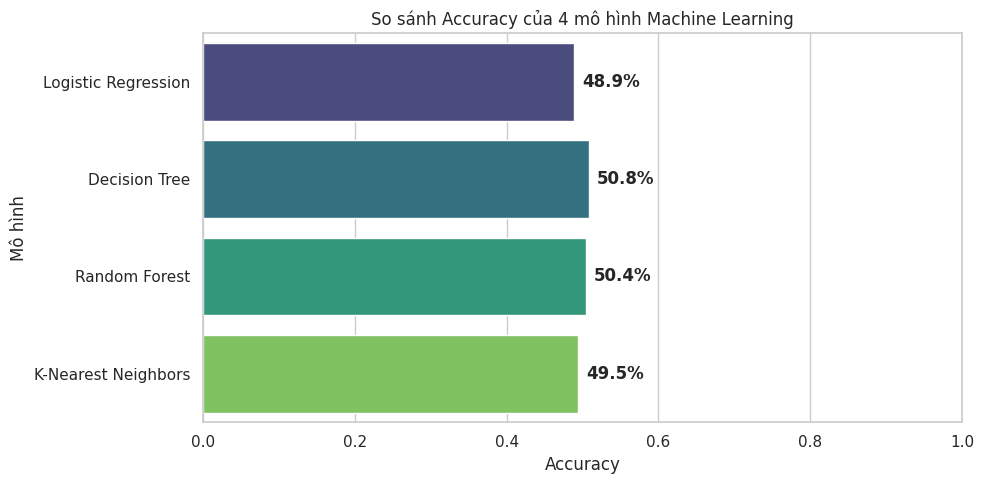

In [9]:

# ==============================================================================
# BƯỚC 1: TẢI THƯ VIỆN VÀ UPLOAD FILE DỮ LIỆU
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Upload file dữ liệu
print("Vui lòng chọn file dữ liệu:")
uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("Bạn chưa tải file dữ liệu lên!")

file_path = list(uploaded.keys())[0]
print(f"-> Đang sử dụng file: {file_path}")


# ==============================================================================
# BƯỚC 2: ĐỌC VÀ KHÁM PHÁ DỮ LIỆU
# ==============================================================================

try:
    if file_path.endswith((".xlsx", ".xls")):
        df = pd.read_excel(file_path)
    else:
        df = pd.read_csv(file_path)

    print("-> Đọc dữ liệu thành công!")

except Exception as e:
    raise ValueError(f"Không thể đọc file. Lỗi: {e}")

# Giới hạn dữ liệu nếu file quá lớn
if len(df) > 20000:
    print("Dữ liệu lớn, lấy ngẫu nhiên 20.000 dòng để xử lý.")
    df = df.sample(n=20000, random_state=42).reset_index(drop=True)

print("\n--- 5 DÒNG ĐẦU TIÊN ---")
display(df.head())

print("\n--- THÔNG TIN DỮ LIỆU ---")
df.info()

print("\n--- KÍCH THƯỚC DỮ LIỆU ---")
print(df.shape)

print("\n--- CÁC CỘT TRONG FILE ---")
print(df.columns.tolist())

print("\n--- SỐ GIÁ TRỊ BỊ THIẾU ---")
print(df.isnull().sum())


# ==============================================================================
# BƯỚC 3: TIỀN XỬ LÝ DỮ LIỆU (DATA PREPROCESSING)
# ==============================================================================

# Xóa các dòng dữ liệu trùng lặp
df = df.drop_duplicates().copy()

# Điền giá trị thiếu ở các cột số
df = df.fillna(df.median(numeric_only=True))

# Tìm cột mục tiêu dự đoán thẻ tín dụng
target_col = None

for c in df.columns:
    ten_cot = c.lower().replace(" ", "").replace("_", "")

    if any(keyword in ten_cot for keyword in [
        "credit", "card", "target", "class", "loan"
    ]):
        target_col = c
        break

# Nếu không tìm thấy cột mục tiêu phù hợp thì tạo cột giả lập
if target_col is None or df[target_col].nunique() <= 1:

    print(
        " Không tìm thấy cột dự đoán thẻ tín dụng phù hợp. "
        "Hệ thống tạo cột CreditCard giả lập để chạy thử mô hình."
    )

    np.random.seed(42)

    # Giả lập dựa trên Salary nếu có, nếu không thì tạo nhãn ngẫu nhiên
    if "Salary" in df.columns and df["Salary"].nunique() > 1:
        df["CreditCard"] = np.where(
            df["Salary"] > df["Salary"].median(), 1, 0
        )
    else:
        df["CreditCard"] = np.random.choice(
            [0, 1], size=len(df)
        )

    target_col = "CreditCard"

print(f"\n-> Cột biến mục tiêu chính thức: '{target_col}'")

# Loại bỏ các cột có quá nhiều giá trị chữ khác nhau
high_cardinality_cols = []

for col in df.select_dtypes(include=["object"]).columns:
    if col != target_col and df[col].nunique() > 15:
        high_cardinality_cols.append(col)

if high_cardinality_cols:
    print("-> Loại bỏ các cột có quá nhiều giá trị:", high_cardinality_cols)

# Loại bỏ các cột không cần thiết
cols_to_drop = [
    c for c in [
        "ID", "Name", "ZIP Code", "ZipCode",
        "JoinDate", "FL_DATE"
    ]
    if c in df.columns and c != target_col
]

cols_to_drop += [
    c for c in high_cardinality_cols if c != target_col
]

# Loại bỏ cột hoàn toàn rỗng
empty_cols = [
    c for c in df.columns if df[c].isnull().all()
]

cols_to_drop = list(set(cols_to_drop + empty_cols))

# Tách dữ liệu đầu vào và kết quả cần dự đoán
X = df.drop(columns=list(set(cols_to_drop + [target_col])))
y = df[target_col]

# Chuyển dữ liệu chữ thành số
X = pd.get_dummies(X, drop_first=True)

# Xử lý giá trị vô hạn và giá trị thiếu
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

# Chuyển nhãn mục tiêu dạng chữ thành số nếu cần
if y.dtype == "object" or str(y.dtype) == "category":
    y = pd.factorize(y)[0]

print("\n-> Số dòng dữ liệu:", len(X))
print("-> Số cột đầu vào:", X.shape[1])
print("-> Các nhãn mục tiêu:", np.unique(y))

# Kiểm tra dữ liệu trước khi chia
if len(X) < 2 or X.shape[1] == 0 or len(np.unique(y)) < 2:
    raise ValueError(
        "Dữ liệu chưa đủ để huấn luyện mô hình. "
        "Hãy kiểm tra lại file dữ liệu."
    )

# Chọn cách chia dữ liệu
class_counts = pd.Series(y).value_counts()
use_stratify = y if class_counts.min() >= 2 else None

# Chia 80% huấn luyện và 20% kiểm tra
test_size = max(1, int(np.ceil(len(X) * 0.2)))

if use_stratify is not None:
    test_size = max(test_size, len(np.unique(y)))

if test_size >= len(X):
    raise ValueError("Không đủ dòng dữ liệu để chia tập huấn luyện.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=test_size,
    random_state=42,
    stratify=use_stratify
)

# Chuẩn hóa dữ liệu
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ==============================================================================
# BƯỚC 4: HUẤN LUYỆN VÀ ĐÁNH GIÁ MÔ HÌNH
# ==============================================================================

# Chọn số hàng xóm không vượt quá số dòng huấn luyện
k = min(5, len(X_train))

models = {
    "Logistic Regression": (
        LogisticRegression(random_state=42, max_iter=1000), True
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42), False
    ),
    "Random Forest": (
        RandomForestClassifier(
            random_state=42, n_estimators=100
        ), False
    ),
    "K-Nearest Neighbors": (
        KNeighborsClassifier(n_neighbors=k), True
    )
}

results = []

for name, (model, is_scaled) in models.items():

    # Chọn dữ liệu phù hợp với mô hình
    if is_scaled:
        X_tr = X_train_scaled
        X_te = X_test_scaled
    else:
        X_tr = X_train
        X_te = X_test

    # Huấn luyện mô hình
    model.fit(X_tr, y_train)

    # Dự đoán kết quả
    y_pred = model.predict(X_te)

    # Tính các chỉ số đánh giá
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    # Tính ROC-AUC cho bài toán phân loại nhị phân
    roc_auc = np.nan

    if len(np.unique(y_test)) == 2 and hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_te)[:, 1]
        roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Mô hình": name,
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4) if not np.isnan(roc_auc) else np.nan
    })

    print(f"-> Đã huấn luyện xong: {name}")

# Hiển thị bảng so sánh
results_df = pd.DataFrame(results)

print("\n========== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ==========")
display(results_df)


# Vẽ biểu đồ cột ngang so sánh Accuracy
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    y="Mô hình",
    x="Accuracy",
    hue="Mô hình",
    legend=False,
    palette="viridis"
)

plt.title("So sánh Accuracy của 4 mô hình Machine Learning")
plt.xlabel("Accuracy")
plt.ylabel("Mô hình")
plt.xlim(0, 1)

# Hiển thị phần trăm ở cuối mỗi cột
for i, row in results_df.iterrows():
    plt.text(
        row["Accuracy"] + 0.01,
        i,
        f'{row["Accuracy"] * 100:.1f}%',
        va="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.show()
